# Food prices in Lusaka

**Dennis Kabaso** — computer science student in Lusaka, learning to work as a data analyst.

White maize and mealie meal are everyday foods here. This notebook asks six plain questions about their prices. The data is retail prices collected by the World Food Programme and published on the Humanitarian Data Exchange (HDX).

Each section is one question, a short pandas calculation, and a chart. Comments mark the choices that would change the answer: the unit, the market, and retail rather than a mixed price type.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

# Works whether Jupyter was started in the project folder or in notebooks/.
ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "data" / "raw" / "wfp_food_prices_zmb.csv").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run this notebook from the project folder so data/raw can be found.")

DATA_PATH = ROOT / "data" / "raw" / "wfp_food_prices_zmb.csv"
IMAGE_DIR = ROOT / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 13


def year_axis(ax, step=1):
    """Label time charts with the year. `step` skips years on long series."""
    ax.xaxis.set_major_locator(mdates.YearLocator(base=step))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def month_axis(ax):
    """Label a short monthly chart without stacking the dates."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

## Load the prices

HDX sometimes inserts a second header row of HXL tags (`#date`, `#adm1+name`, and so on). This copy does not have that row. The loader skips it only when it is present, so a fresh download still works.

`priceflag` can be `actual` (a market observation) or `aggregate` (a WFP summary). The charts use actual prices only.

In [2]:
def load_wfp_prices(path):
    """Read the WFP CSV, skipping an HXL tag row when row 2 is tags rather than a price."""
    preview = pd.read_csv(path, nrows=2, header=None, dtype=str)
    first_value = str(preview.iloc[1, 0])
    if first_value.startswith("#"):
        print("Skipped the HXL tag row under the header.")
        prices = pd.read_csv(path, skiprows=[1])
    else:
        print("No HXL tag row in this file. Row 2 is already a price.")
        prices = pd.read_csv(path)

    prices["date"] = pd.to_datetime(prices["date"])
    prices["price"] = pd.to_numeric(prices["price"])
    prices["usdprice"] = pd.to_numeric(prices["usdprice"])
    return prices


raw = load_wfp_prices(DATA_PATH)
prices = raw[raw["priceflag"] == "actual"].copy()

# Stop if a later file mixes in wholesale or another currency.
assert set(prices["pricetype"]) == {"Retail"}
assert set(prices["currency"]) == {"ZMW"}
assert (prices["price"] > 0).all()
assert (prices["usdprice"] > 0).all()

# The file spells Muchinga as "Muchiga". Charts use the usual province name.
prices["province"] = prices["admin1"].replace({"Muchiga": "Muchinga"})

print(f"{len(prices):,} retail rows kept ({len(raw) - len(prices):,} aggregate rows set aside).")
print(f"Dates: {prices['date'].min():%d %b %Y} to {prices['date'].max():%d %b %Y}.")
print(f"Provinces: {prices['province'].nunique()}. Markets: {prices['market'].nunique()}.")
display(
    prices[
        ["date", "province", "admin2", "market", "commodity", "unit", "pricetype", "currency", "price", "usdprice"]
    ].head()
)

No HXL tag row in this file. Row 2 is already a price.
71,289 retail rows kept (1,915 aggregate rows set aside).
Dates: 15 Jan 2003 to 15 Jun 2026.
Provinces: 10. Markets: 209.


,date,province,admin2,market,commodity,unit,pricetype,currency,price,usdprice
0,2003-01-15,Central,Kabwe,Kabwe Rural,Maize (white),KG,Retail,ZMW,1.00,0.22
1,2003-01-15,Central,Kabwe,Kabwe Urban,Maize (white),KG,Retail,ZMW,1.11,0.25
2,2003-01-15,Central,Mkushi,Mkushi Itala,Maize (white),KG,Retail,ZMW,1.07,0.24
3,2003-01-15,Central,Mumbwa,Mumbwa,Maize (white),KG,Retail,ZMW,1.15,0.25
4,2003-01-15,Central,Serenje,Serenje,Maize (white),KG,Retail,ZMW,1.15,0.25


## Same unit, same kind of price

A kilogram of loose grain, a 20 litre tin, and a 25 kg bag are different quotes. This file has no wholesale prices at all: every row is retail, in ZMW. Comparisons below stay inside one unit.

In [3]:
focus = [
    "Maize (white)",
    "Maize meal (white, breakfast)",
    "Maize meal (white, roller)",
    "Fuel (petrol-gasoline)",
    "Fuel (diesel)",
]
units = (
    prices[prices["commodity"].isin(focus)]
    .groupby(["commodity", "unit", "pricetype"])
    .agg(rows=("price", "size"), first=("date", "min"), last=("date", "max"))
    .sort_values(["commodity", "unit"])
)
units["first"] = units["first"].dt.strftime("%b %Y")
units["last"] = units["last"].dt.strftime("%b %Y")
display(units)

rows     first      last
commodity                     unit       pricetype                           
Fuel (diesel)                 L          Retail        90  Jan 2015  Aug 2022
Fuel (petrol-gasoline)        L          Retail        90  Jan 2015  Aug 2022
Maize (white)                 KG         Retail     10559  Jan 2003  Aug 2022
                              Tin (20 L) Retail      1697  Nov 2023  Sep 2025
Maize meal (white, breakfast) 25 KG      Retail      2098  Nov 2023  Sep 2025
                              KG         Retail      6797  Mar 2012  Apr 2021
Maize meal (white, roller)    25 KG      Retail      1455  Nov 2023  Sep 2025
                              KG         Retail      5400  May 2012  Aug 2022

## 1. How have white maize and mealie meal prices in Lusaka moved since 2003?

"Lusaka" here is Lusaka district (`admin2`), not the whole province. Luangwa, Kafue, and Chongwe have their own markets and are left out.

WFP renamed the city markets. Up to 2012 the file has **Lusaka Urban** and **Lusaka Rural**. After that the market is just **Lusaka**. When both old markets reported a month, the chart uses the median so the month still counts once.

Mealie meal was not collected per kilogram in 2003. Breakfast and roller meal join the chart when those kilogram quotes exist. The kilogram series then stops, and later years switch to a tin and a 25 kg bag. Those later units are not drawn here.

White maize markets in this series: Lusaka, Lusaka Rural, Lusaka Urban


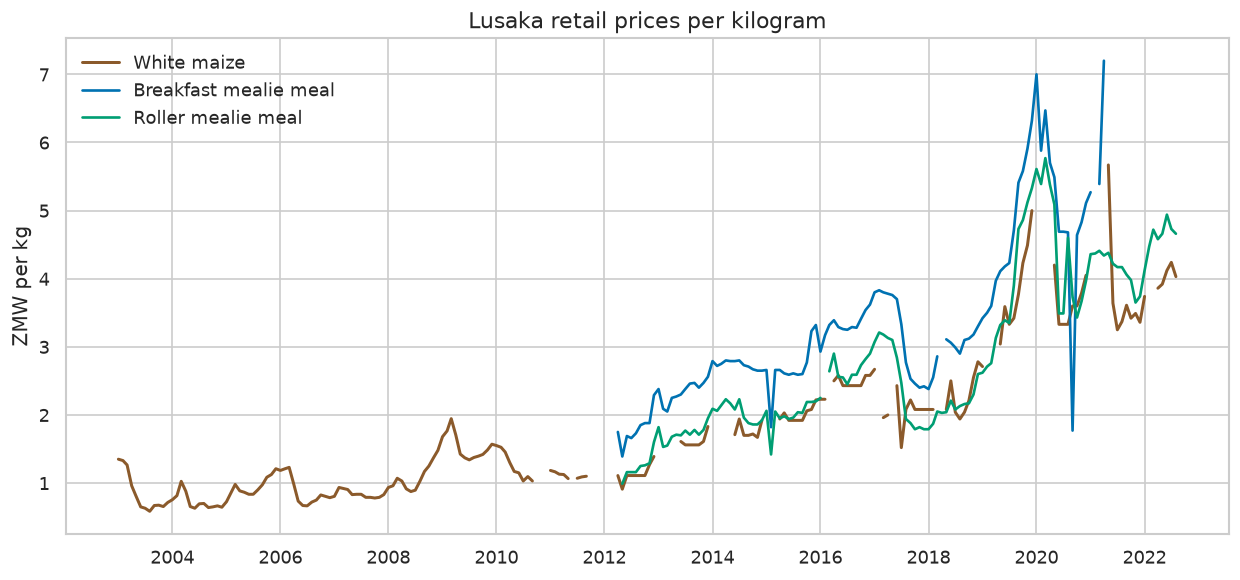

White maize averaged 0.86 ZMW/kg in 2003 (12 months), 1.08 in 2008, 1.54 in 2009, 2.00 in 2015, and 3.74 in 2021 (9 months).
Lowest month: 0.58 ZMW/kg in Aug 2003. Highest month: 5.67 ZMW/kg in May 2021.
Last per-kilogram maize quote: 4.03 ZMW/kg in Aug 2022.
Breakfast mealie meal per kg runs Apr 2012 to Apr 2021.
Roller mealie meal per kg runs May 2012 to Aug 2022.
Later maize quotes are a 20 L tin, and later mealie meal quotes are a 25 kg bag. They are not on this chart.


In [4]:
# Lusaka district only. Other districts in Lusaka province stay out of this trend.
lusaka_district = (prices["province"] == "Lusaka") & (prices["admin2"] == "Lusaka")

maize = prices[
    lusaka_district
    & (prices["commodity"] == "Maize (white)")
    & (prices["unit"] == "KG")
].copy()
print("White maize markets in this series:", ", ".join(sorted(maize["market"].unique())))

maize["month"] = maize["date"].dt.to_period("M")
maize_month = maize.groupby("month").agg(maize_zmw=("price", "median"), maize_usd=("usdprice", "median"))


def monthly_city_price(commodity, unit):
    """Median retail price at the market named Lusaka, one unit only."""
    subset = prices[
        lusaka_district
        & (prices["market"] == "Lusaka")
        & (prices["commodity"] == commodity)
        & (prices["unit"] == unit)
    ].copy()
    subset["month"] = subset["date"].dt.to_period("M")
    return subset.groupby("month")["price"].median()


breakfast_kg = monthly_city_price("Maize meal (white, breakfast)", "KG").rename("breakfast_zmw")
roller_kg = monthly_city_price("Maize meal (white, roller)", "KG").rename("roller_zmw")

trend = maize_month.join(breakfast_kg, how="outer").join(roller_kg, how="outer")
# Reindex so a missing month is a gap in the line, not a point joined to the next quote.
trend = trend.reindex(pd.period_range(trend.index.min(), trend.index.max(), freq="M"))
trend.index = trend.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10.5, 5))
ax.plot(trend.index, trend["maize_zmw"], color="#8B5A2B", linewidth=1.8, label="White maize")
ax.plot(trend.index, trend["breakfast_zmw"], color="#0072B2", linewidth=1.6, label="Breakfast mealie meal")
ax.plot(trend.index, trend["roller_zmw"], color="#009E73", linewidth=1.6, label="Roller mealie meal")
ax.set_title("Lusaka retail prices per kilogram")
ax.set_ylabel("ZMW per kg")
ax.set_xlabel("")
ax.legend(frameon=False)
year_axis(ax, step=2)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "01_lusaka_price_trend.png", bbox_inches="tight", facecolor="white")
plt.show()


def year_mean(series, year):
    values = series[series.index.year == year].dropna()
    return values.mean(), len(values)


m2003, n2003 = year_mean(trend["maize_zmw"], 2003)
m2008, _ = year_mean(trend["maize_zmw"], 2008)
m2009, _ = year_mean(trend["maize_zmw"], 2009)
m2015, _ = year_mean(trend["maize_zmw"], 2015)
m2021, n2021 = year_mean(trend["maize_zmw"], 2021)
maize_kg = trend["maize_zmw"].dropna()

print(
    f"White maize averaged {m2003:.2f} ZMW/kg in 2003 ({n2003} months), "
    f"{m2008:.2f} in 2008, {m2009:.2f} in 2009, {m2015:.2f} in 2015, "
    f"and {m2021:.2f} in 2021 ({n2021} months)."
)
print(
    f"Lowest month: {maize_kg.min():.2f} ZMW/kg in {maize_kg.idxmin():%b %Y}. "
    f"Highest month: {maize_kg.max():.2f} ZMW/kg in {maize_kg.idxmax():%b %Y}."
)
print(f"Last per-kilogram maize quote: {maize_kg.iloc[-1]:.2f} ZMW/kg in {maize_kg.index[-1]:%b %Y}.")
print(
    f"Breakfast mealie meal per kg runs {trend['breakfast_zmw'].dropna().index.min():%b %Y} "
    f"to {trend['breakfast_zmw'].dropna().index.max():%b %Y}."
)
print(
    f"Roller mealie meal per kg runs {trend['roller_zmw'].dropna().index.min():%b %Y} "
    f"to {trend['roller_zmw'].dropna().index.max():%b %Y}."
)
print("Later maize quotes are a 20 L tin, and later mealie meal quotes are a 25 kg bag. They are not on this chart.")

**Answer.** Retail white maize in Lusaka district averaged **0.86 ZMW/kg in 2003** (12 months) and **3.74 ZMW/kg in 2021** (9 months). It did not rise in a straight line: the average was **1.08** in 2008, **1.54** in 2009, and **2.00** in 2015. The lowest month was **0.58 ZMW/kg in Aug 2003**. The highest was **5.67 ZMW/kg in May 2021**. The last per-kilogram quote is **4.03 ZMW/kg in Aug 2022**.

Breakfast mealie meal per kilogram is on the chart from **Apr 2012 to Apr 2021**, and roller meal from **May 2012 to Aug 2022**. A 20 L tin of maize and a 25 kg bag of mealie meal come later, so they are not drawn on this per-kilogram chart.

## 2. Which months are the most expensive?

A plain average by calendar month would mostly reflect recent years, because prices are much higher now than in 2003. Instead, each month is divided by **that year's own average**. A value of 1.10 means "10% above a typical month in the same year."

Years with fewer than 10 maize quotes are left out, so a half-year does not set the average. Red bars are months above the year's average.

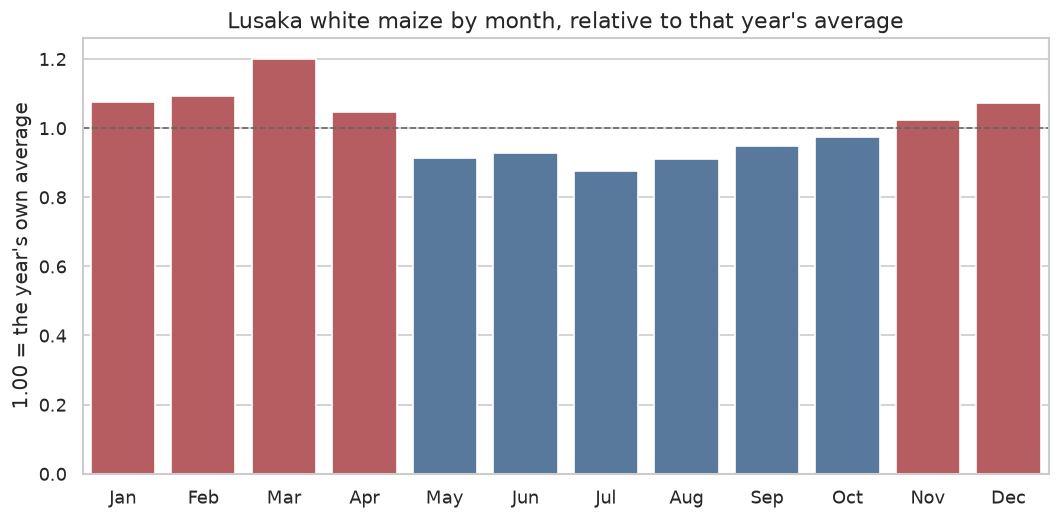

Years used (11): 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2012, 2016, 2017, 2018.
Highest: Mar at 1.20 (20.0% above the year's average).
Lowest: Jul at 0.88 (12.4% below the year's average).
Months above the year's average: Jan, Feb, Mar, Apr, Nov, Dec.


In [5]:
maize_obs = trend["maize_zmw"].dropna().to_frame("price")
maize_obs["year"] = maize_obs.index.year
maize_obs["month"] = maize_obs.index.month

months_per_year = maize_obs.groupby("year")["month"].nunique()
full_years = months_per_year[months_per_year >= 10].index
season = maize_obs[maize_obs["year"].isin(full_years)].copy()
season["year_avg"] = season.groupby("year")["price"].transform("mean")
season["index"] = season["price"] / season["year_avg"]
seasonal = season.groupby("month")["index"].mean()

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season_plot = pd.DataFrame(
    {"month": month_labels, "index": [seasonal.loc[month] for month in range(1, 13)]}
)
palette = {
    label: "#C44E52" if value > 1 else "#4C78A8"
    for label, value in zip(season_plot["month"], season_plot["index"])
}

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=season_plot, x="month", y="index", hue="month", palette=palette, legend=False, ax=ax)
ax.axhline(1, color="#666666", linestyle="--", linewidth=1)
ax.set_title("Lusaka white maize by month, relative to that year's average")
ax.set_ylabel("1.00 = the year's own average")
ax.set_xlabel("")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "02_lean_season.png", bbox_inches="tight", facecolor="white")
plt.show()

peak_month = int(seasonal.idxmax())
trough_month = int(seasonal.idxmin())
above = [month_labels[month - 1] for month in range(1, 13) if seasonal.loc[month] > 1]
print(f"Years used ({len(full_years)}): {', '.join(str(year) for year in full_years)}.")
print(
    f"Highest: {month_labels[peak_month - 1]} at {seasonal.loc[peak_month]:.2f} "
    f"({(seasonal.loc[peak_month] - 1) * 100:.1f}% above the year's average)."
)
print(
    f"Lowest: {month_labels[trough_month - 1]} at {seasonal.loc[trough_month]:.2f} "
    f"({(1 - seasonal.loc[trough_month]) * 100:.1f}% below the year's average)."
)
print("Months above the year's average: " + ", ".join(above) + ".")

**Answer.** **March** is the expensive month. In the 11 years with at least 10 quotes (2003–2009, 2012, and 2016–2018), March maize was **20.0% above** that year's average (index **1.20**). **July** was the cheapest, **12.4% below** (index **0.88**). January, February, March, April, November, and December all sit above the year's average. Those high months are the lean season before the main harvest. May to October, after harvest, are cheaper.

## 3. Is breakfast mealie meal more expensive than roller meal?

Breakfast meal is milled finer than roller meal, so shoppers expect it to cost more. The fair comparison uses the same market (the one named Lusaka), the same price type (retail), and the same unit.

The kilogram quotes and the later 25 kg bag quotes are different products on the shelf. They are plotted side by side and are not joined into one price per kilogram.

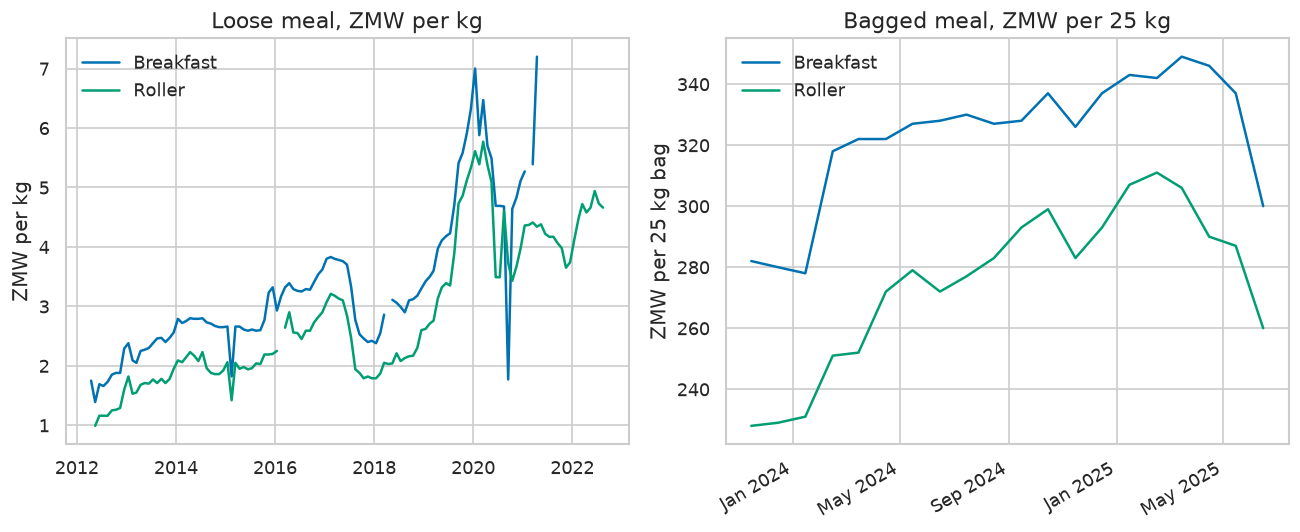

Per kg, 105 months quote both (May 2012 to Apr 2021).
Average breakfast 3.32 ZMW/kg, roller 2.61 ZMW/kg.
Breakfast premium on the kilogram quotes: mean 31%, median 32%.
25 kg bags, 20 months quote both (Nov 2023 to Jun 2025).
Average bag: breakfast 323 ZMW, roller 275 ZMW (premium 18%).
Months where breakfast was cheaper than roller: 1.
  Sep 2020: breakfast 1.77 ZMW/kg, roller 3.73 ZMW/kg.


In [6]:
city_meal = prices[
    lusaka_district
    & (prices["market"] == "Lusaka")
    & prices["commodity"].isin(["Maize meal (white, breakfast)", "Maize meal (white, roller)"])
].copy()


def meal_pair(frame):
    wide = frame.pivot_table(index="date", columns="commodity", values="price", aggfunc="median").sort_index()
    return wide.rename(
        columns={
            "Maize meal (white, breakfast)": "breakfast",
            "Maize meal (white, roller)": "roller",
        }
    )


kg_wide = meal_pair(city_meal[city_meal["unit"] == "KG"])
bag_wide = meal_pair(city_meal[city_meal["unit"] == "25 KG"])
both_kg = kg_wide.dropna().copy()
both_bag = bag_wide.dropna().copy()
both_kg["premium"] = both_kg["breakfast"] / both_kg["roller"] - 1
both_bag["premium"] = both_bag["breakfast"] / both_bag["roller"] - 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].plot(kg_wide.index, kg_wide["breakfast"], color="#0072B2", label="Breakfast")
axes[0].plot(kg_wide.index, kg_wide["roller"], color="#009E73", label="Roller")
axes[0].set_title("Loose meal, ZMW per kg")
axes[0].set_ylabel("ZMW per kg")
axes[0].legend(frameon=False)
year_axis(axes[0], step=2)

axes[1].plot(bag_wide.index, bag_wide["breakfast"], color="#0072B2", label="Breakfast")
axes[1].plot(bag_wide.index, bag_wide["roller"], color="#009E73", label="Roller")
axes[1].set_title("Bagged meal, ZMW per 25 kg")
axes[1].set_ylabel("ZMW per 25 kg bag")
axes[1].legend(frameon=False)
month_axis(axes[1])
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "03_breakfast_vs_roller.png", bbox_inches="tight", facecolor="white")
plt.show()

print(
    f"Per kg, {len(both_kg)} months quote both ({both_kg.index.min():%b %Y} to {both_kg.index.max():%b %Y})."
)
print(
    f"Average breakfast {both_kg['breakfast'].mean():.2f} ZMW/kg, roller {both_kg['roller'].mean():.2f} ZMW/kg."
)
print(
    f"Breakfast premium on the kilogram quotes: mean {both_kg['premium'].mean() * 100:.0f}%, "
    f"median {both_kg['premium'].median() * 100:.0f}%."
)
print(
    f"25 kg bags, {len(both_bag)} months quote both ({both_bag.index.min():%b %Y} to {both_bag.index.max():%b %Y})."
)
print(
    f"Average bag: breakfast {both_bag['breakfast'].mean():.0f} ZMW, roller {both_bag['roller'].mean():.0f} ZMW "
    f"(premium {both_bag['premium'].mean() * 100:.0f}%)."
)
below = both_kg[both_kg["breakfast"] < both_kg["roller"]]
print(f"Months where breakfast was cheaper than roller: {len(below)}.")
for quoted_on, row in below.iterrows():
    print(f"  {quoted_on:%b %Y}: breakfast {row['breakfast']:.2f} ZMW/kg, roller {row['roller']:.2f} ZMW/kg.")

**Answer.** Yes. On the Lusaka market, breakfast meal cost more than roller meal in both units.

Over **105 months** from **May 2012 to Apr 2021**, breakfast averaged **3.32 ZMW/kg** and roller **2.61 ZMW/kg**. The mean premium was **31%** and the median premium was **32%**. Breakfast was cheaper in one month only: **Sep 2020**, at **1.77 ZMW/kg** against roller at **3.73 ZMW/kg**. That quote is far below the months on either side, and it stays in the average because the file marks it as an actual price.

On **25 kg bags** (**20 months**, **Nov 2023 to Jun 2025**), breakfast averaged **323 ZMW** and roller **275 ZMW**, a premium of **18%**. The bag prices are not converted to a per-kilogram series.

## 4. Which provinces have the most and least expensive maize?

Provinces are compared on **white maize, retail, one unit at a time**. The long comparable series is the kilogram, for 2019–2021, the last three calendar years before kilogram quotes stop. The recent series is the 20 L tin. A tin is not converted to kilograms, because that would require guessing how tightly the grain is packed.

Within a province, each market-month is one price. The province-month price is the median market, so a province with more markets does not automatically look more expensive. The bar is then the median of those months. Lusaka is in red.

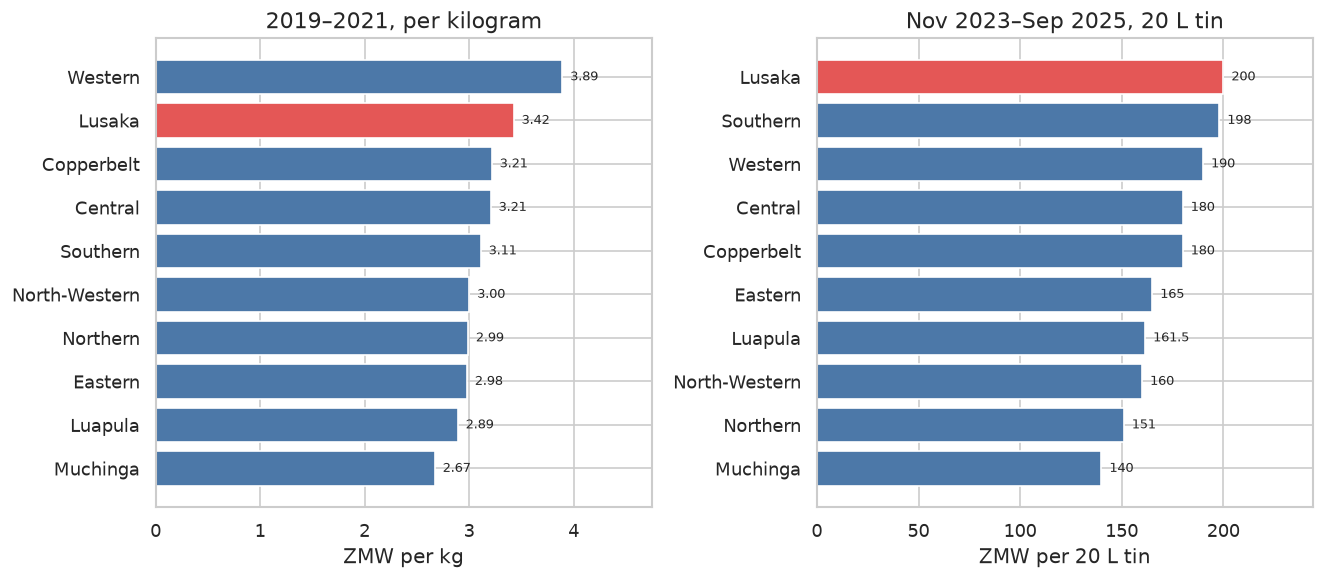

Kilogram window: Jan 2019 to Dec 2021.


,median_price,months
province,,
Western,3.89,35
Lusaka,3.42,36
Copperbelt,3.22,36
Central,3.20,36
Southern,3.11,35
North-Western,3.00,35
Northern,2.99,36
Eastern,2.98,36
Luapula,2.89,36


Per kg, dearest: Western at 3.89 ZMW. Cheapest: Muchinga at 2.67 ZMW. Lusaka: 3.42 ZMW.
Western is 46% above Muchinga.
Tin window: Nov 2023 to Sep 2025. Not converted to kilograms.


,median_price,months
province,,
Lusaka,200.0,20
Southern,198.0,22
Western,190.0,23
Central,180.0,23
Copperbelt,180.0,23
Eastern,165.0,22
Luapula,161.5,23
North-Western,160.0,23
Northern,151.0,23


Per 20 L tin, dearest: Lusaka at 200 ZMW. Cheapest: Muchinga at 140 ZMW.
Southern tin median: 198 ZMW (22 months). Lusaka tin months: 20.


In [7]:
def province_median(frame):
    """One median price per province: market-month, then province-month, then across months."""
    market_month = (
        frame.groupby(["province", "market", frame["date"].dt.to_period("M")])["price"]
        .median()
        .reset_index(name="price")
    )
    province_month = market_month.groupby(["province", "date"])["price"].median().reset_index(name="price")
    summary = province_month.groupby("province")["price"].agg(median_price="median", months="count")
    return summary.sort_values(["median_price", "province"], ascending=[False, True])


kg_window = prices[
    (prices["commodity"] == "Maize (white)")
    & (prices["unit"] == "KG")
    & (prices["date"] >= "2019-01-01")
    & (prices["date"] <= "2021-12-31")
]
tin_window = prices[(prices["commodity"] == "Maize (white)") & (prices["unit"] == "Tin (20 L)")]
kg_rank = province_median(kg_window)
tin_rank = province_median(tin_window)


def rank_bars(ax, summary, xlabel, title):
    ordered = summary.sort_values(["median_price", "province"], ascending=[True, False])
    colors = ["#E45756" if name == "Lusaka" else "#4C78A8" for name in ordered.index]
    ax.barh(ordered.index.astype(str), ordered["median_price"], color=colors)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.set_xlim(0, ordered["median_price"].max() * 1.22)
    for name, value in ordered["median_price"].items():
        if value < 50:
            label = f"{value:.2f}"
        elif abs(value - round(value)) < 0.05:
            label = f"{value:.0f}"
        else:
            label = f"{value:.1f}"
        ax.text(value, str(name), f"  {label}", va="center", ha="left", fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(11.2, 5))
rank_bars(axes[0], kg_rank, "ZMW per kg", "2019–2021, per kilogram")
rank_bars(
    axes[1],
    tin_rank,
    "ZMW per 20 L tin",
    f"{tin_window['date'].min():%b %Y}–{tin_window['date'].max():%b %Y}, 20 L tin",
)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "04_maize_price_by_province.png", bbox_inches="tight", facecolor="white")
plt.show()

print(f"Kilogram window: {kg_window['date'].min():%b %Y} to {kg_window['date'].max():%b %Y}.")
display(kg_rank.round({"median_price": 2}))
dearest_kg = kg_rank["median_price"].max()
cheapest_kg = kg_rank["median_price"].min()
dearest_kg_names = ", ".join(kg_rank.index[kg_rank["median_price"] == dearest_kg])
cheapest_kg_names = ", ".join(kg_rank.index[kg_rank["median_price"] == cheapest_kg])
print(
    f"Per kg, dearest: {dearest_kg_names} at {dearest_kg:.2f} ZMW. "
    f"Cheapest: {cheapest_kg_names} at {cheapest_kg:.2f} ZMW. "
    f"Lusaka: {kg_rank.loc['Lusaka', 'median_price']:.2f} ZMW."
)
print(f"{dearest_kg_names} is {(dearest_kg / cheapest_kg - 1) * 100:.0f}% above {cheapest_kg_names}.")

print(
    f"Tin window: {tin_window['date'].min():%b %Y} to {tin_window['date'].max():%b %Y}. "
    "Not converted to kilograms."
)
display(tin_rank.round({"median_price": 2}))
dearest_tin = tin_rank["median_price"].max()
cheapest_tin = tin_rank["median_price"].min()
print(
    "Per 20 L tin, dearest: "
    + ", ".join(tin_rank.index[tin_rank["median_price"] == dearest_tin])
    + f" at {dearest_tin:.0f} ZMW. Cheapest: "
    + ", ".join(tin_rank.index[tin_rank["median_price"] == cheapest_tin])
    + f" at {cheapest_tin:.0f} ZMW."
)
print(
    "Southern tin median: "
    f"{tin_rank.loc['Southern', 'median_price']:.0f} ZMW "
    f"({int(tin_rank.loc['Southern', 'months'])} months). "
    f"Lusaka tin months: {int(tin_rank.loc['Lusaka', 'months'])}."
)

**Answer.** On retail white maize **per kilogram in 2019–2021**, **Western** was dearest at **3.89 ZMW/kg** (35 months) and **Muchinga** was cheapest at **2.67 ZMW/kg** (36 months). Western was **46%** above Muchinga. **Lusaka** was second dearest at **3.42 ZMW/kg** (36 months).

On the **20 L tin** from **Nov 2023 to Sep 2025**, **Lusaka** was dearest at **200 ZMW** (20 months) and **Muchinga** was again cheapest at **140 ZMW** (23 months). **Southern** was close behind Lusaka at **198 ZMW** (22 months). The dearest province changes with the unit and the years. The cheapest, Muchinga, does not. The file spells that province `Muchiga`.

## 5. Do petrol and diesel move with food prices?

Fuel in this file is retail, in ZMW per litre, and it is recorded only at the Lusaka market, from 2015 to 2022. The food series next to it is white maize and roller mealie meal at that same market, per kilogram.

Two checks are easy to mix up. Prices can all drift upward for years (correlation of the **levels**) even when a fuel jump this month does not show up in maize this month (correlation of the **percent changes**). The chart indexes every series to the first month in which petrol, diesel, and maize were all quoted.

Fuel markets in the whole file: Lusaka


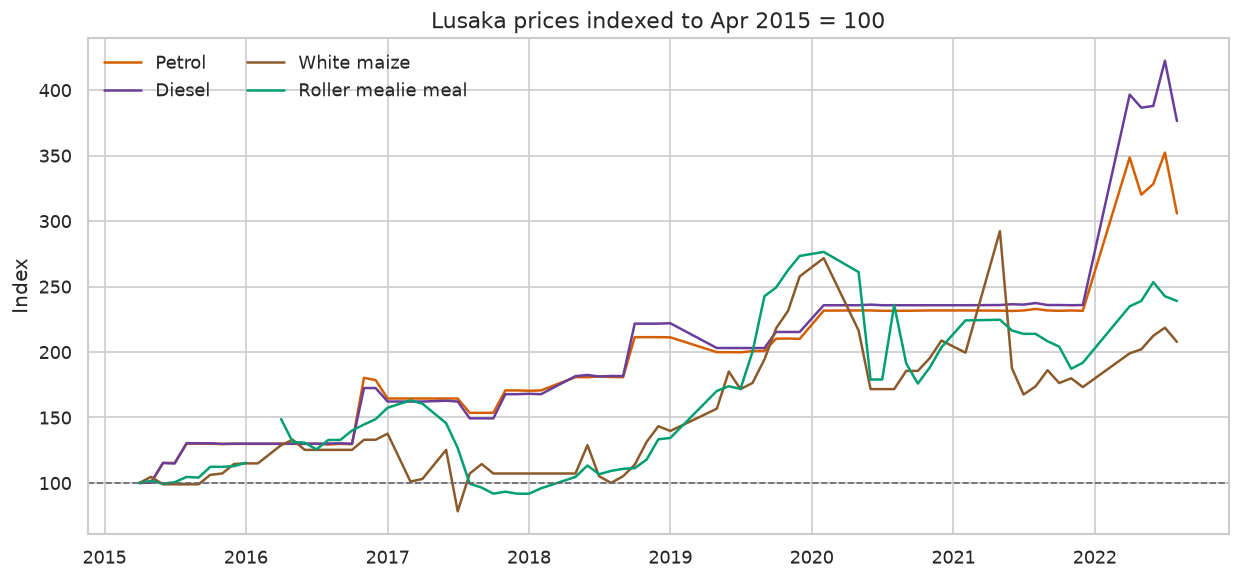

Overlap: 72 months, Apr 2015 to Aug 2022.
Petrol 7.60 to 23.24 ZMW/L (3.06x).
Diesel 6.61 to 24.88 ZMW/L (3.76x).
Maize 1.94 to 4.03 ZMW/kg (2.08x).
Correlation of price levels, petrol and maize: 0.73.
Correlation of monthly percent changes, petrol and maize: 0.09.
Correlation of year-on-year changes, petrol and maize: -0.03.
Diesel and maize: monthly changes 0.09, year-on-year -0.05.


In [8]:
city = prices[lusaka_district & (prices["market"] == "Lusaka")].copy()
fuel_markets = prices.loc[prices["commodity"].str.startswith("Fuel"), "market"].unique()
print("Fuel markets in the whole file:", ", ".join(sorted(fuel_markets)))


def city_series(commodity, unit):
    subset = city[(city["commodity"] == commodity) & (city["unit"] == unit)].copy()
    subset["month"] = subset["date"].dt.to_period("M")
    return subset.groupby("month")["price"].median()


panel = pd.DataFrame(
    {
        "petrol": city_series("Fuel (petrol-gasoline)", "L"),
        "diesel": city_series("Fuel (diesel)", "L"),
        "maize": city_series("Maize (white)", "KG"),
        "roller": city_series("Maize meal (white, roller)", "KG"),
    }
)
# Inner join on the three series the question compares. Roller is plotted where it exists.
overlap = panel.dropna(subset=["petrol", "diesel", "maize"]).copy()
indexed = pd.DataFrame(index=overlap.index)
for column in ["petrol", "diesel", "maize", "roller"]:
    indexed[column] = overlap[column] / overlap[column].dropna().iloc[0] * 100
indexed.index = indexed.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10.5, 5))
ax.plot(indexed.index, indexed["petrol"], color="#D55E00", label="Petrol")
ax.plot(indexed.index, indexed["diesel"], color="#6A3D9A", label="Diesel")
ax.plot(indexed.index, indexed["maize"], color="#8B5A2B", label="White maize")
ax.plot(indexed.index, indexed["roller"], color="#009E73", label="Roller mealie meal")
ax.axhline(100, color="#666666", linestyle="--", linewidth=1)
start = overlap.index.min().to_timestamp()
ax.set_title(f"Lusaka prices indexed to {start:%b %Y} = 100")
ax.set_ylabel("Index")
ax.set_xlabel("")
ax.legend(frameon=False, ncol=2)
year_axis(ax)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "05_fuel_and_food.png", bbox_inches="tight", facecolor="white")
plt.show()

level_corr = overlap[["petrol", "diesel", "maize"]].corr()
change_corr = overlap[["petrol", "diesel", "maize"]].pct_change().corr()
yoy_corr = overlap[["petrol", "diesel", "maize"]].pct_change(12).corr()
base = overlap.iloc[0]
end = overlap.dropna(subset=["petrol", "diesel", "maize"]).iloc[-1]

print(
    f"Overlap: {len(overlap)} months, {start:%b %Y} to {overlap.index.max().to_timestamp():%b %Y}."
)
print(f"Petrol {base['petrol']:.2f} to {end['petrol']:.2f} ZMW/L ({end['petrol'] / base['petrol']:.2f}x).")
print(f"Diesel {base['diesel']:.2f} to {end['diesel']:.2f} ZMW/L ({end['diesel'] / base['diesel']:.2f}x).")
print(f"Maize {base['maize']:.2f} to {end['maize']:.2f} ZMW/kg ({end['maize'] / base['maize']:.2f}x).")
print(f"Correlation of price levels, petrol and maize: {level_corr.loc['petrol', 'maize']:.2f}.")
print(f"Correlation of monthly percent changes, petrol and maize: {change_corr.loc['petrol', 'maize']:.2f}.")
print(f"Correlation of year-on-year changes, petrol and maize: {yoy_corr.loc['petrol', 'maize']:.2f}.")
print(
    f"Diesel and maize: monthly changes {change_corr.loc['diesel', 'maize']:.2f}, "
    f"year-on-year {yoy_corr.loc['diesel', 'maize']:.2f}."
)

**Answer.** They rise together over the years, and they do not move together month to month.

Fuel is quoted only at the Lusaka market. Over the **72 months** from **Apr 2015 to Aug 2022** when petrol, diesel, and maize were all recorded, petrol went from **7.60 to 23.24 ZMW/L (3.06×)**, diesel from **6.61 to 24.88 ZMW/L (3.76×)**, and white maize from **1.94 to 4.03 ZMW/kg (2.08×)**. The correlation of the price **levels** is **0.73** for petrol and maize. The correlation of **monthly percent changes** is **0.09** for petrol and maize, and **0.09** for diesel and maize. Year-on-year changes correlate **-0.03** (petrol and maize) and **-0.05** (diesel and maize). A shared upward trend is not the same thing as maize following fuel from one month to the next.

## 6. How much of the kwacha increase is the currency?

`price` is kwacha per kilogram. `usdprice` is the same observation converted to US dollars by WFP. Dividing them gives the kwacha-per-dollar rate implied by the file. That is not an official Bank of Zambia rate, and it is not a price anyone paid in dollars at the market.

The maize series is the same Lusaka district kilogram series as in question 1. Annual averages use the months that were actually collected. 2003 has all 12 months. 2021 does not, so the month count is printed with the average.

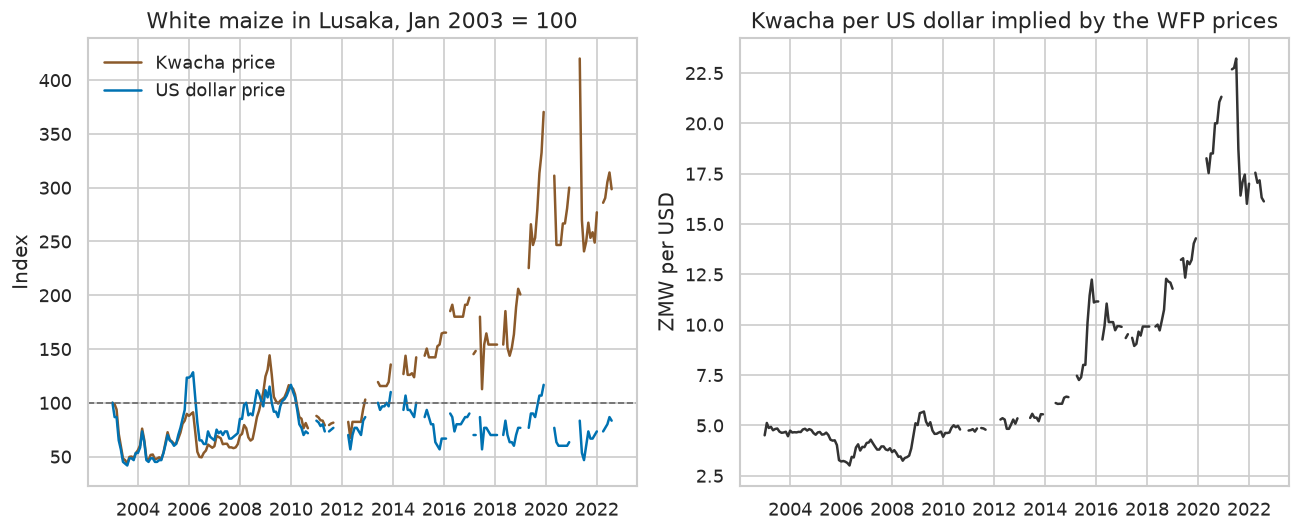

2003 average (12 months): 0.86 ZMW/kg, 0.18 USD/kg, 4.74 ZMW per USD.
2021 average (9 months): 3.74 ZMW/kg, 0.19 USD/kg, 19.54 ZMW per USD.
From the 2003 average to the 2021 average, the kwacha price was 4.36 times as high and the dollar price was 1.07 times as high.
Last kilogram month, Aug 2022: 4.03 ZMW/kg, 0.25 USD/kg, 16.12 ZMW per USD.


In [9]:
maize_fx = maize.copy()
maize_fx["fx"] = maize_fx["price"] / maize_fx["usdprice"]
fx_month = maize_fx.groupby("month").agg(zmw=("price", "median"), usd=("usdprice", "median"), fx=("fx", "median"))
fx_plot = fx_month.reindex(pd.period_range(fx_month.index.min(), fx_month.index.max(), freq="M"))
fx_plot.index = fx_plot.index.to_timestamp()

base_row = fx_plot.dropna(subset=["zmw", "usd"]).iloc[0]
indexed_fx = pd.DataFrame(
    {
        "Kwacha price": fx_plot["zmw"] / base_row["zmw"] * 100,
        "US dollar price": fx_plot["usd"] / base_row["usd"] * 100,
    }
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].plot(indexed_fx.index, indexed_fx["Kwacha price"], color="#8B5A2B", label="Kwacha price")
axes[0].plot(indexed_fx.index, indexed_fx["US dollar price"], color="#0072B2", label="US dollar price")
axes[0].axhline(100, color="#666666", linestyle="--", linewidth=1)
axes[0].set_title(f"White maize in Lusaka, {base_row.name:%b %Y} = 100")
axes[0].set_ylabel("Index")
axes[0].legend(frameon=False)
year_axis(axes[0], step=2)
axes[1].plot(fx_plot.index, fx_plot["fx"], color="#333333")
axes[1].set_title("Kwacha per US dollar implied by the WFP prices")
axes[1].set_ylabel("ZMW per USD")
year_axis(axes[1], step=2)
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "06_kwacha_vs_usd.png", bbox_inches="tight", facecolor="white")
plt.show()

y2003 = fx_month[fx_month.index.year == 2003]
y2021 = fx_month[fx_month.index.year == 2021]
last = fx_month.iloc[-1]
print(
    f"2003 average ({len(y2003)} months): {y2003['zmw'].mean():.2f} ZMW/kg, "
    f"{y2003['usd'].mean():.2f} USD/kg, {y2003['fx'].mean():.2f} ZMW per USD."
)
print(
    f"2021 average ({len(y2021)} months): {y2021['zmw'].mean():.2f} ZMW/kg, "
    f"{y2021['usd'].mean():.2f} USD/kg, {y2021['fx'].mean():.2f} ZMW per USD."
)
print(
    f"From the 2003 average to the 2021 average, the kwacha price was "
    f"{y2021['zmw'].mean() / y2003['zmw'].mean():.2f} times as high and the dollar price was "
    f"{y2021['usd'].mean() / y2003['usd'].mean():.2f} times as high."
)
print(
    f"Last kilogram month, {fx_month.index[-1].to_timestamp():%b %Y}: "
    f"{last['zmw']:.2f} ZMW/kg, {last['usd']:.2f} USD/kg, {last['fx']:.2f} ZMW per USD."
)

**Answer.** Most of the rise in the kwacha price is the exchange rate.

The 2003 average (12 months) was **0.86 ZMW/kg** and **0.18 USD/kg**, which implies **4.74 ZMW per USD**. The 2021 average (9 months) was **3.74 ZMW/kg** and **0.19 USD/kg**, which implies **19.54 ZMW per USD**. From 2003 to 2021 the kwacha price became **4.36 times** as high. The dollar price became **1.07 times** as high. In the last kilogram month, **Aug 2022**, maize was **4.03 ZMW/kg** and **0.25 USD/kg**, and the implied rate was **16.12 ZMW per USD**.

`usdprice` is WFP's conversion, so the right-hand chart is the rate implied by these two columns, not a Bank of Zambia fixing.

## What this does not show

- There is no wholesale file here, so retail and wholesale are never mixed, and wholesale is not analysed.
- Per-kilogram maize in Lusaka ends in 2022. Per-kilogram mealie meal ends in 2021 (breakfast) or 2022 (roller). The 20 L tin and the 25 kg bag are separate charts.
- Some months are missing. The month-of-year chart drops years with fewer than 10 quotes.
- The dollar column is WFP's conversion. The kwacha-per-dollar line is implied by `price / usdprice`.
- Petrol and diesel are only at the Lusaka market, and only through August 2022.
- The source spelling of Muchinga province is `Muchiga`.